In [1]:
import pandas as pd
from datasets import load_dataset
from dotenv import load_dotenv
from utils.helper_fuctions import plot_bar_grid, create_model, plot_benchmark
from utils.model_functions import call_chat_model, call_jev
from utils.model_evaluation import evaluate_model
from typing import Literal
from pydantic import BaseModel, Field

load_dotenv()

/Users/georgestavrakis/Documents/Projects/Medium_Articles/Jev_Walkthrough/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [ ]:
# Initialize an empty DataFrame to store the final results
evaluation_df = pd.DataFrame()

# GPT models to analyse
gpt_models=["gpt-6.1-sol","gpt-6-luna", "gpt-5.4-mini"]


## Product Reviews Classifier

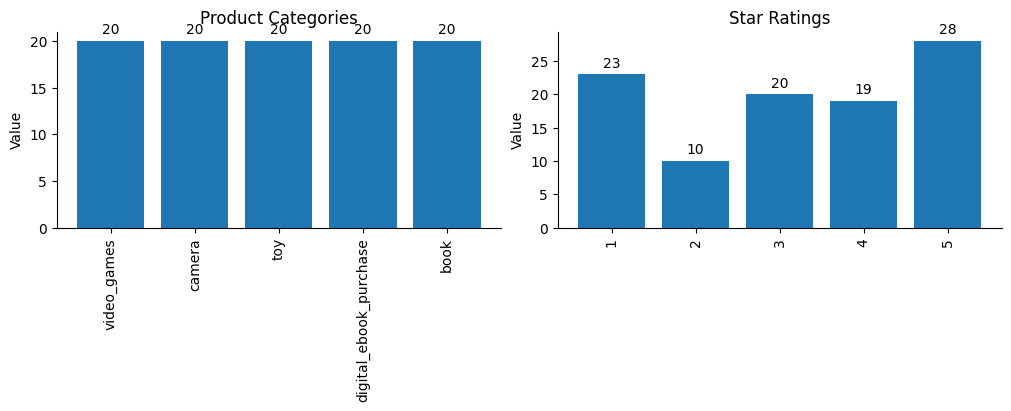

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'Product Categories'}, ylabel='Value'>,
         <Axes: title={'center': 'Star Ratings'}, ylabel='Value'>]],
       dtype=object))

In [3]:
# Loading the Amazon Reviews Multi dataset
ds = load_dataset("goosmanlei/amazon_reviews_multi", "en", split="test")
df_reviews = ds.to_pandas()

# Selecting a subset of the dataset for demonstration purposes
products = ["book", "digital_ebook_purchase", "camera", "toy", "video_games"]

# Creating a balanced dataset with equal representation of each product category
n_total = 100
label_col = "product_category"

labels = products
n_classes = len(labels)

n_per_class, remainder = divmod(n_total, n_classes)

df_reviews_balanced = pd.concat([
    df_reviews[df_reviews[label_col] == label].sample(
        n=n_per_class + (i < remainder),
        random_state=42
    )
    for i, label in enumerate(labels)
]).sample(frac=1, random_state=42).reset_index(drop=True)

plot_bar_grid({"Product Categories": df_reviews_balanced[label_col].value_counts(), "Star Ratings": df_reviews_balanced.stars.value_counts()}, ncols=2)

### Jev Run

In [4]:
questions = {"product_category": {"type": "choice",
    "instructions": "Classify the product category based on the 'review_title' and 'review_body'.",
        "criteria":{
        "book": "Physical printed books, including novels, textbooks, and nonfiction.",
        "digital_ebook_purchase": "Digital books purchased and read electronically, such as Kindle eBooks.",
        "camera": "Cameras, photography equipment, lenses, and related accessories.",
        "toy": "Toys, games, and play products for children and adults, excluding video games.",
        "video_games": "Video games, gaming consoles, controllers, and related gaming accessories."}
        },
        "rating": {"type": "choice",
    "instructions": "Rate the product based on the 'review_title' and 'review_body' on a scale of 1 to 5, where 1 is the lowest rating and 5 is the highest rating.",
        "criteria":{
        "1": "Very poor quality or performance, does not meet expectations.",
        "2": "Below average quality or performance, some issues present.",
        "3": "Average quality or performance, meets basic expectations.",
        "4": "Good quality or performance, exceeds expectations in some areas.",
        "5": "Excellent quality or performance, far exceeds expectations."}
        }
    }

final_results = {
    "product_categories": [],
    "ratings": [],
    "costs": [],
    "latencies": [],
    "actual_categories": [],
    "actual_ratings": [],
    "categories_labels": list(set(df_reviews_balanced.product_category.to_list())),
    "ratings_labels": list(set(df_reviews_balanced.stars.to_list())),
}

for i in range(df_reviews_balanced.shape[0]):

    review_title = df_reviews_balanced['review_title'][i]
    review_body = df_reviews_balanced['review_body'][i]

    state = {"review_title": review_title,  
                "review_body": review_body}
    categories = ['product_category', 'rating']

    results = call_jev(state, questions, categories)

    final_results["actual_categories"].append(df_reviews_balanced['product_category'][i])
    final_results["actual_ratings"].append(int(df_reviews_balanced['stars'][i]))
    final_results["product_categories"].append(results['product_category'])
    final_results["ratings"].append(int(results['rating']))
    final_results["costs"].append(results['cost'])
    final_results["latencies"].append(results['latency'])

categories_metrics = evaluate_model(
    y_true=final_results['actual_categories'], 
    y_pred=final_results['product_categories'],
    latencies=final_results['latencies'],
    costs=final_results['costs'], 
    labels=final_results['categories_labels']
    )

ratings_metrics = evaluate_model(
    y_true=final_results['actual_ratings'], 
    y_pred=final_results['ratings'],
    latencies=final_results['latencies'],
    costs=final_results['costs'], 
    labels=final_results['ratings_labels']
    )

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV",
        "dataset": "Amazon Reviews Multi",
        "task": "Product Category Classification",
        **{k: v for k, v in categories_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV",
        "dataset": "Amazon Reviews Multi",
        "task": "Product Ratings Classification",
        **{k: v for k, v in ratings_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

display(evaluation_df)


,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.716634,0.710000,0.660110,0.660110,0.19714,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.63,0.594639,0.609566,0.594639,0.585774,0.639429,0.19714,0.190589,0.236661,0.327057,0.002724,0.027244


In [5]:
evaluation_df.to_csv('final_results.csv')

### Chat model run

In [ ]:
# For chat model
class QuestionSchema(BaseModel):
    product_category: Literal[
        "book",
        "digital_ebook_purchase",
        "camera",
        "toy",
        "video_games"
    ] = Field(
        description=(
            "Classify the product category based on the 'review_title' and 'review_body'.\n"
            "Criteria:\n"
            "- book: Physical printed books, including novels, textbooks, and nonfiction.\n"
            "- digital_ebook_purchase: Digital books purchased and read electronically, such as Kindle eBooks.\n"
            "- camera: Cameras, photography equipment, lenses, and related accessories.\n"
            "- toy: Toys, games, and play products for children and adults, excluding video games.\n"
            "- video_games: Video games, gaming consoles, controllers, and related gaming accessories."
        )
    )

    rating: Literal[1, 2, 3, 4, 5] = Field(
        description=(
            "Rate the product based on the 'review_title' and 'review_body' on a scale of 1 to 5, where 1 is the lowest rating and 5 is the highest rating.\n"
            "Criteria:\n"
            "- 1: Very poor quality or performance, does not meet expectations.\n"
            "- 2: Below average quality or performance, some issues present.\n"
            "- 3: Average quality or performance, meets basic expectations.\n"
            "- 4: Good quality or performance, exceeds expectations in some areas.\n"
            "- 5: Excellent quality or performance, far exceeds expectations."
        )
    )


final_results = {
    "product_categories": [],
    "ratings": [],
    "costs": [],
    "latencies": [],
    "actual_categories": [],
    "actual_ratings": [],
    "categories_labels": list(set(df_reviews_balanced.product_category.to_list())),
    "ratings_labels": list(set(df_reviews_balanced.stars.to_list())),
}


for model in gpt_models:

    for i in range(df_reviews_balanced.shape[0]):

        review_title = df_reviews_balanced['review_title'][i]
        review_body = df_reviews_balanced['review_body'][i]

        prompt_template = f"""
            Classify the following product review based on the provided instructions and criteria.

            Review Title: {review_title}
            Review Body: {review_body}

            product_category:
            Instructions: Classify the product category based on the 'review_title' and 'review_body'.
            Criteria:
            - book: Physical printed books, including novels, textbooks, and nonfiction.
            - digital_ebook_purchase: Digital books purchased and read electronically, such as Kindle eBooks.
            - camera: Cameras, photography equipment, lenses, and related accessories.
            - toy: Toys, games, and play products for children and adults, excluding video games.
            - video_games: Video games, gaming consoles, controllers, and related gaming accessories.

            rating:
            Instructions: Rate the product based on the 'review_title' and 'review_body' on a scale of 1 to 5, where 1 is the lowest rating and 5 is the highest rating.
            Criteria:
            - 1: Very poor quality or performance, does not meet expectations.
            - 2: Below average quality or performance, some issues present.
            - 3: Average quality or performance, meets basic expectations.
            - 4: Good quality or performance, exceeds expectations in some areas.
            - 5: Excellent quality or performance, far exceeds expectations.
            """

        prompt = prompt_template.format(review_title, review_body)

        categories = ['product_category', 'rating']

        results = call_chat_model(prompt=prompt, categories=categories, model_name=model, schema_class=QuestionSchema)

        final_results["actual_categories"].append(df_reviews_balanced['product_category'][i])
        final_results["actual_ratings"].append(df_reviews_balanced['stars'][i])
        final_results["product_categories"].append(results['product_category'])
        final_results["ratings"].append(results['rating'])
        final_results["costs"].append(results['cost'])
        final_results["latencies"].append(results['latency'])

    categories_metrics = evaluate_model(y_true=final_results['actual_categories'], y_pred=final_results['product_categories'],latencies=final_results['latencies'],costs=final_results['costs'], labels=final_results['categories_labels'])
    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "Amazon Reviews Multi",
            "task": "Product Category Classification",
            **{k: v for k, v in categories_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)
    
    ratings_metrics = evaluate_model(y_true=final_results['actual_ratings'], y_pred=final_results['ratings'], latencies=final_results['latencies'], costs=final_results['costs'], labels=final_results['ratings_labels'])

    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "Amazon Reviews Multi",
            "task": "Product ratings Classification",
            **{k: v for k, v in categories_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)

display(evaluation_df)

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.710000,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.630000,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,200,0.760000,0.760000,0.851019,0.760000,0.718907,0.718907,2.010282,1.867852,2.878868,3.937452,0.297150,1.485750
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,200,0.760000,0.760000,0.851019,0.760000,0.718907,0.718907,2.010282,1.867852,2.878868,3.937452,0.297150,1.485750
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,300,0.756667,0.756667,0.849883,0.756667,0.714808,0.714808,1.993839,1.856976,2.841911,3.901356,0.445490,1.484967
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,300,0.756667,0.756667,0.849883,0.756667,0.714808,0.714808,1.993839,1.856976,2.841911,3.901356,0.445490,1.484967


In [23]:
evaluation_df.to_csv('final_results.csv')

## Groundness Evaluator

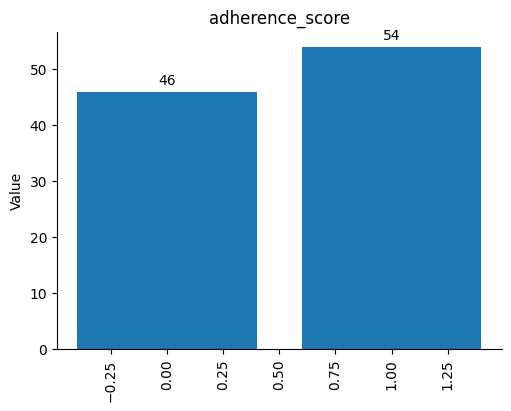

(<Figure size 500x400 with 1 Axes>,
 array([[<Axes: title={'center': 'adherence_score'}, ylabel='Value'>]],
       dtype=object))

In [9]:
from datasets import load_dataset

# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("galileo-ai/ragbench", "techqa", split="test")

groundness_df = ds.to_pandas()
groundness_df = groundness_df.sample(n=100, random_state=42).reset_index(drop=True)

plot_bar_grid({"adherence_score": groundness_df["adherence_score"].value_counts()}, ncols=1)

In [11]:
questions = {
    "groundedness": {
        "type": "choice",
        "instructions": "Determine whether every factual claim in the 'response' is fully supported by the provided 'documents', considering the original 'question'.",
        "criteria": {
            "grounded": "Every factual claim in the response is supported by the provided context.",
            "ungrounded": "At least one factual claim in the response is unsupported or contradicted by the provided context."
        }
    }
}

final_results = {
    "groundedness": [],
    "costs": [],
    "latencies": [],
    "actual_groundedness": [],
    "groundedness_labels": ["grounded", "ungrounded"],
}

for i in range(groundness_df.shape[0]):

    question = groundness_df["question"][i]
    documents = groundness_df["documents"][i]
    response = groundness_df["response"][i]

    state = {
        "question": question,
        "documents": list(documents),
        "response": response
    }

    categories = ["groundedness"]

    results = call_jev(state, questions, categories)

    actual_label = ("grounded" if groundness_df["adherence_score"][i] else "ungrounded")

    final_results["actual_groundedness"].append(actual_label)
    final_results["groundedness"].append(
        results["groundedness"]
    )
    final_results["costs"].append(results["cost"])
    final_results["latencies"].append(results["latency"])

groundness_metrics = evaluate_model(
    y_true=final_results["actual_groundedness"],
    y_pred=final_results["groundedness"],
    latencies=final_results["latencies"],
    costs=final_results["costs"],
    labels=final_results["groundedness_labels"]
)

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV", 
        "dataset": "RAGBench Groundedness",
        "task": "Groundedness Verification",
        **{k: v for k, v in groundness_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

In [12]:
display(evaluation_df)

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.710000,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.630000,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,200,0.760000,0.760000,0.851019,0.760000,0.718907,0.718907,2.010282,1.867852,2.878868,3.937452,0.297150,1.485750
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,200,0.760000,0.760000,0.851019,0.760000,0.718907,0.718907,2.010282,1.867852,2.878868,3.937452,0.297150,1.485750
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,300,0.756667,0.756667,0.849883,0.756667,0.714808,0.714808,1.993839,1.856976,2.841911,3.901356,0.445490,1.484967
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,300,0.756667,0.756667,0.849883,0.756667,0.714808,0.714808,1.993839,1.856976,2.841911,3.901356,0.445490,1.484967
8,JEV,RAGBench Groundedness,Groundedness Verification,100,0.780000,0.789855,0.800000,0.789855,0.779205,0.778145,0.239335,0.223014,0.339862,0.393615,0.025549,0.255489


In [13]:
evaluation_df.to_csv('final_results.csv')

In [19]:
class QuestionSchema(BaseModel):

    groundedness: Literal[
        "grounded",
        "ungrounded"
    ] = Field(
        description=(
            "Determine whether every factual claim in the 'response' "
            "is fully supported by the provided 'documents', "
            "considering the original 'question'.\n"
            "Criteria:\n"
            "- grounded: Every factual claim in the response is supported by the provided context.\n"
            "- ungrounded: At least one factual claim in the response is unsupported or contradicted by the provided context."
        )
    )

final_results = {
    "groundedness": [],
    "costs": [],
    "latencies": [],
    "actual_groundedness": [],
    "groundedness_labels": ["grounded", "ungrounded"],
}

for model in gpt_models:

    for i in range(groundness_df.shape[0]):

        question = groundness_df["question"][i]
        documents = groundness_df["documents"][i]
        response = groundness_df["response"][i]

        prompt_template = f"""
            Classify whether the following LLM response is grounded in the provided documents.

            question: {question}

            documents:
            {chr(10).join(f"- {doc}" for doc in documents)}

            response: {response}

            groundedness:
            Instructions: Determine whether every factual claim in the 'response' is fully supported by the provided 'documents', considering the original 'question'.
            Criteria:
            - grounded: Every factual claim in the response is supported by the provided context.
            - ungrounded: At least one factual claim in the response is unsupported or contradicted by the provided context.
        """

        prompt = prompt_template

        categories = ["groundedness"]

        results = call_chat_model(
            prompt=prompt,
            categories=categories,
            model_name="gpt-6.1-sol",
            schema_class=QuestionSchema
        )

        actual_label = (
            "grounded"
            if groundness_df["adherence_score"][i]
            else "ungrounded"
        )

        final_results["actual_groundedness"].append(actual_label)
        final_results["groundedness"].append(
            results["groundedness"]
        )
        final_results["costs"].append(results["cost"])
        final_results["latencies"].append(results["latency"])

    groundness_metrics = evaluate_model(
        y_true=final_results["actual_groundedness"],
        y_pred=final_results["groundedness"],
        latencies=final_results["latencies"],
        costs=final_results["costs"],
        labels=final_results["groundedness_labels"]
    )

    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "RAGBench Groundedness",
            "task": "Groundedness Verification",
            **{k: v for k, v in groundness_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)

display(evaluation_df)

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.710000,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.630000,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,200,0.760000,0.760000,0.851019,0.760000,0.718907,0.718907,2.010282,1.867852,2.878868,3.937452,0.297150,1.485750
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,200,0.760000,0.760000,0.851019,0.760000,0.718907,0.718907,2.010282,1.867852,2.878868,3.937452,0.297150,1.485750
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,300,0.756667,0.756667,0.849883,0.756667,0.714808,0.714808,1.993839,1.856976,2.841911,3.901356,0.445490,1.484967
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,300,0.756667,0.756667,0.849883,0.756667,0.714808,0.714808,1.993839,1.856976,2.841911,3.901356,0.445490,1.484967
8,JEV,RAGBench Groundedness,Groundedness Verification,100,0.780000,0.789855,0.800000,0.789855,0.779205,0.778145,0.239335,0.223014,0.339862,0.393615,0.025549,0.255489
9,gpt-6.1-sol,RAGBench Groundedness,Groundedness Verification,100,0.740000,0.752818,0.772569,0.752818,0.737374,0.735273,2.189817,1.913051,3.984538,5.043944,1.083664,10.836640


In [29]:
evaluation_df.to_csv('final_results.csv')

## Banking Intent classification

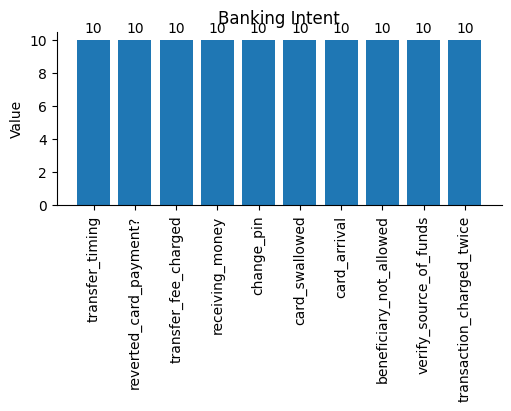

(<Figure size 500x400 with 1 Axes>,
 array([[<Axes: title={'center': 'Banking Intent'}, ylabel='Value'>]],
       dtype=object))

In [30]:
# Banking intent dataset
url = (
    "https://raw.githubusercontent.com/"
    "PolyAI-LDN/task-specific-datasets/"
    "master/banking_data/test.csv"
)

banking = pd.read_csv(url)

banking_sample = banking.sample(
    n=100,
    random_state=42
).reset_index(drop=True)


selected_intents = banking["category"].value_counts().head(10).index

banking_sample = (
    banking[banking["category"].isin(selected_intents)]
    .groupby("category", group_keys=False)
    .sample(n=10, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

plot_bar_grid({"Banking Intent": banking_sample["category"].value_counts()}, ncols=1)

In [32]:
questions = {
    "intent": {
        "type": "choice",
        "instructions": "Classify the user's banking intent based on the 'text'. Select the category that best represents the user's primary request.",
        "criteria": {
            "verify_source_of_funds": "Questions about verifying or providing evidence of where deposited or transferred funds originated.",
            "card_swallowed": "Issues involving an ATM retaining or swallowing a customer's bank card.",
            "transaction_charged_twice": "Issues where a customer has been charged twice for the same transaction.",
            "receiving_money": "Questions about receiving money into a bank account from another person or account.",
            "card_arrival": "Questions about the delivery status or expected arrival time of a bank card.",
            "transfer_fee_charged": "Questions or complaints about fees charged for transferring money.",
            "change_pin": "Requests to change or update the PIN associated with a bank card.",
            "reverted_card_payment?": "Questions about card payments being reversed, refunded, or returned to the customer's account.",
            "transfer_timing": "Questions about how long a bank transfer takes to process or reach the recipient.",
            "beneficiary_not_allowed": "Issues where a money transfer is blocked because the recipient or beneficiary is not permitted."
        }
    }
}

final_results = {
    "bank_categories": [],
    "ratings": [],
    "costs": [],
    "latencies": [],
    "actual_categories": [],
    "actual_ratings": [],
    "categories_labels": list(set(banking_sample.category.to_list()))
}

for i in range(banking_sample.shape[0]):

    text = banking_sample['text'][i]

    state = {"text": text}
    categories = ["intent"]

    results = call_jev(state, questions, categories)

    final_results["actual_categories"].append(banking_sample['category'][i])
    final_results["bank_categories"].append(results["intent"])
    final_results["costs"].append(results['cost'])
    final_results["latencies"].append(results['latency'])


categories_metrics = evaluate_model(y_true=final_results['actual_categories'], y_pred=final_results['bank_categories'],latencies=final_results['latencies'],costs=final_results['costs'], labels=final_results['categories_labels'])

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV", 
        "dataset": "BANKING77 Intent Dataset",
        "task": "Banking Intents Classification",
        **{k: v for k, v in categories_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

display(evaluation_df)

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.63,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.76,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.76,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,100,0.71,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,200,0.70,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,200,0.70,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
8,JEV,RAGBench Groundedness,Groundedness Verification,100,0.78,0.789855,0.800000,0.789855,0.779205,0.778145,0.239335,0.223014,0.339862,0.393615,0.025549,0.255489
9,gpt-6.1-sol,RAGBench Groundedness,Groundedness Verification,100,0.74,0.752818,0.772569,0.752818,0.737374,0.735273,2.189817,1.913051,3.984538,5.043944,1.083664,10.836640


In [42]:
intent_labels = sorted(banking_sample["category"].unique().tolist())

# Dynamic Literal because BANKING77 contains 77 intents
QuestionSchema = create_model(
    "QuestionSchema",
    intent=(
        Literal[tuple(intent_labels)],
        Field(
            description=(
                "Classify the user's banking intent based on the 'text'. "
                "Select the category that best represents the user's primary request.\n"
                "Criteria:\n"
                "- verify_source_of_funds: Questions about verifying or providing evidence of where deposited or transferred funds originated.\n"
                "- card_swallowed: Issues involving an ATM retaining or swallowing a customer's bank card.\n"
                "- transaction_charged_twice: Issues where a customer has been charged twice for the same transaction.\n"
                "- receiving_money: Questions about receiving money into a bank account from another person or account.\n"
                "- card_arrival: Questions about the delivery status or expected arrival time of a bank card.\n"
                "- transfer_fee_charged: Questions or complaints about fees charged for transferring money.\n"
                "- change_pin: Requests to change or update the PIN associated with a bank card.\n"
                "- reverted_card_payment?: Questions about card payments being reversed, refunded, or returned to the customer's account.\n"
                "- transfer_timing: Questions about how long a bank transfer takes to process or reach the recipient.\n"
                "- beneficiary_not_allowed: Issues where a money transfer is blocked because the recipient or beneficiary is not permitted.\n"
            )
        )
    )
)

final_results = {
    "intents": [],
    "costs": [],
    "latencies": [],
    "actual_intents": [],
    "intent_labels": intent_labels,
}


for model in gpt_models:

    for i in range(banking_sample.shape[0]):

        text = banking_sample["text"][i]

        prompt_template = f"""
            Classify the following banking request based on the provided instructions and criteria.

            text: {text}

            intent:
            Instructions: Classify the user's banking intent based on the 'text'. Select the category that best represents the user's primary request.
            Criteria:
            - verify_source_of_funds: Questions about verifying or providing evidence of where deposited or transferred funds originated.
            - card_swallowed: Issues involving an ATM retaining or swallowing a customer's bank card.
            - transaction_charged_twice: Issues where a customer has been charged twice for the same transaction.
            - receiving_money: Questions about receiving money into a bank account from another person or account.
            - card_arrival: Questions about the delivery status or expected arrival time of a bank card.
            - transfer_fee_charged: Questions or complaints about fees charged for transferring money.
            - change_pin: Requests to change or update the PIN associated with a bank card.
            - reverted_card_payment?: Questions about card payments being reversed, refunded, or returned to the customer's account.
            - transfer_timing: Questions about how long a bank transfer takes to process or reach the recipient.
            - beneficiary_not_allowed: Issues where a money transfer is blocked because the recipient or beneficiary is not permitted.
        """

        prompt = prompt_template.format(text)
        categories = ["intent"]

        results = call_chat_model(prompt=prompt, categories=categories, model_name=model, schema_class=QuestionSchema)

        final_results["actual_intents"].append(banking_sample["category"][i])
        final_results["intents"].append(results["intent"])
        final_results["costs"].append(results["cost"])
        final_results["latencies"].append(results["latency"])

    categories_metrics = evaluate_model(y_true=final_results["actual_intents"],y_pred=final_results["intents"],latencies=final_results["latencies"],costs=final_results["costs"], labels=final_results["intent_labels"])

    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "BANKING77 Intent Dataset",
            "task": "Banking Intents Classification",
            **{k: v for k, v in categories_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)

display(evaluation_df) 

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.63,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.76,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.76,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,100,0.71,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,200,0.70,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,200,0.70,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
8,JEV,RAGBench Groundedness,Groundedness Verification,100,0.78,0.789855,0.800000,0.789855,0.779205,0.778145,0.239335,0.223014,0.339862,0.393615,0.025549,0.255489
9,gpt-6.1-sol,RAGBench Groundedness,Groundedness Verification,100,0.74,0.752818,0.772569,0.752818,0.737374,0.735273,2.189817,1.913051,3.984538,5.043944,1.083664,10.836640


In [44]:
evaluation_df.to_csv('final_results.csv')

## Ticketing Support Router

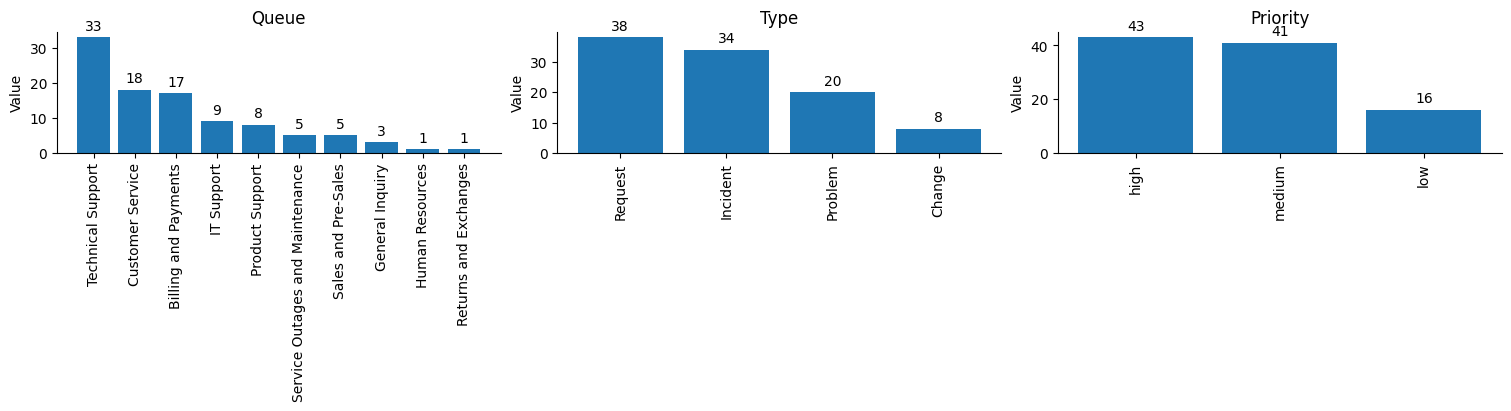

(<Figure size 1500x400 with 3 Axes>,
 array([[<Axes: title={'center': 'Queue'}, ylabel='Value'>,
         <Axes: title={'center': 'Type'}, ylabel='Value'>,
         <Axes: title={'center': 'Priority'}, ylabel='Value'>]],
       dtype=object))

In [60]:
from datasets import load_dataset

ds = load_dataset("Tobi-Bueck/customer-support-tickets", split="train")
df_tickets = ds.to_pandas()
df_tickets = df_tickets[df_tickets['language']=='en']
df_tickets = df_tickets.sample(n=100, random_state=45).reset_index(drop=True)

plot_bar_grid({"Queue": df_tickets['queue'].value_counts(), "Type": df_tickets['type'].value_counts(), "Priority": df_tickets['priority'].value_counts()}, ncols=3)

In [61]:
queue_labels = sorted(df_tickets["queue"].dropna().unique().tolist())
priority_labels = sorted(df_tickets["priority"].dropna().astype(str).unique().tolist())
type_labels = sorted(df_tickets["type"].dropna().unique().tolist())

questions = {
    "queue": {
        "type": "choice",
        "instructions": "Classify the appropriate support queue based on the 'subject' and 'body'. Select the team best suited to handle the ticket.",
        "criteria": {
            "Technical Support": "Technical issues and support requests.",
            "Customer Service": "Customer inquiries and service requests.",
            "Billing and Payments": "Billing issues and payment processing.",
            "Product Support": "Support for product-related issues.",
            "IT Support": "Internal IT support and infrastructure issues.",
            "Returns and Exchanges": "Product returns and exchanges.",
            "Sales and Pre-Sales": "Sales inquiries and pre-sales questions.",
            "Human Resources": "Employee inquiries and HR-related issues.",
            "Service Outages and Maintenance": "Service interruptions and maintenance.",
            "General Inquiry": "General inquiries and information requests."
        }
    },
    "priority": {
        "type": "choice",
        "instructions": "Classify the ticket priority based on the 'subject' and 'body', considering urgency, business impact, and the need for immediate action.",
        "criteria": {
            "low": "Low priority. A routine request or minor issue that does not require immediate attention.",
            "medium": "Medium priority. An issue that requires timely resolution but is not critical.",
            "high": "Critical priority. An urgent issue causing significant disruption or requiring immediate action."
        }
    },
    "type": {
        "type": "choice",
        "instructions": "Classify the ticket type based on the 'subject' and 'body'.",
        "criteria": {
            "Change": "Requests to modify, update, or improve existing systems, services, configurations, or processes.",
            "Incident": "Unexpected disruptions, failures, or degradations affecting the normal operation of a system or service.",
            "Problem": "Underlying or recurring issues requiring investigation to identify and resolve the root cause of one or more incidents.",
            "Request": "Routine requests for information, access, assistance, or standard services that do not involve system failures."
        }
    }
}


final_results = {
    "queues": [],
    "priorities": [],
    "types": [],
    "costs": [],
    "latencies": [],
    "actual_queues": [],
    "actual_priorities": [],
    "actual_types": [],
    "queue_labels": queue_labels,
    "priority_labels": priority_labels,
    "type_labels": type_labels,
}

for i in range(df_tickets.shape[0]):

    subject = df_tickets["subject"][i]
    body = df_tickets["body"][i]

    state = {
        "subject": subject,
        "body": body
    }

    categories = ["queue", "priority", "type"]

    results = call_jev(state, questions, categories)

    final_results["actual_queues"].append(df_tickets["queue"][i])
    final_results["actual_priorities"].append(str(df_tickets["priority"][i]))
    final_results["actual_types"].append(df_tickets["type"][i])

    final_results["queues"].append(results["queue"])
    final_results["priorities"].append(str(results["priority"]))
    final_results["types"].append(results["type"])
    final_results["costs"].append(results["cost"])
    final_results["latencies"].append(results["latency"])

queue_metrics = evaluate_model(
    y_true=final_results["actual_queues"],
    y_pred=final_results["queues"],
    latencies=final_results["latencies"],
    costs=final_results["costs"],
    labels=final_results["queue_labels"]
)

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV", 
        "dataset": "Customer Support Tickets",
        "task": "Ticket Classification",
        **{k: v for k, v in queue_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

priority_metrics = evaluate_model(
    y_true=final_results["actual_priorities"],
    y_pred=final_results["priorities"],
    labels=final_results["priority_labels"]
)

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV", 
        "dataset": "Customer Support Tickets",
        "task": "Ticket Priority Identification",
        **{k: v for k, v in priority_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

type_metrics = evaluate_model(
    y_true=final_results["actual_types"],
    y_pred=final_results["types"],
    labels=final_results["type_labels"]
)

# Add model, dataset, and task information
evaluation_df = pd.concat([
    evaluation_df,
    pd.DataFrame([{
        "model": "JEV", 
        "dataset": "Customer Support Tickets",
        "task": "Ticket Type Classification",
        **{k: v for k, v in type_metrics.items()if k not in ["confusion_matrix", "per_class"]}
    }])], ignore_index=True)

display(evaluation_df)

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.63,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.76,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.76,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,100,0.71,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,100,0.71,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,200,0.70,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,200,0.70,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
8,JEV,RAGBench Groundedness,Groundedness Verification,100,0.78,0.789855,0.800000,0.789855,0.779205,0.778145,0.239335,0.223014,0.339862,0.393615,0.025549,0.255489
9,gpt-6.1-sol,RAGBench Groundedness,Groundedness Verification,100,0.74,0.752818,0.772569,0.752818,0.737374,0.735273,2.189817,1.913051,3.984538,5.043944,1.083664,10.836640


In [62]:
queue_labels = sorted(df_tickets["queue"].dropna().unique().tolist())
priority_labels = sorted(df_tickets["priority"].dropna().astype(str).unique().tolist())
type_labels = sorted(df_tickets["type"].dropna().unique().tolist())

class QuestionSchema(BaseModel):

    queue: Literal[
        "Billing and Payments",
        "Customer Service",
        "Human Resources",
        "IT Support",
        "Product Support",
        "Returns and Exchanges",
        "Sales and Pre-Sales",
        "Service Outages and Maintenance",
        "Technical Support"
    ] = Field(
        description=(
            "Classify the appropriate support queue based on the 'subject' and 'body'. "
            "Select the team best suited to handle the ticket.\n"
            "Criteria:\n"
            "-Technical Support:  Technical issues and support requests.\n"
            "-Customer Service: Customer inquiries and service requests.\n"
            "-Billing and Payments: Billing issues and payment processing.\n"
            "-Product Support: Support for product-related issues.\n"
            "-IT Support: Internal IT support and infrastructure issues.\n"
            "-Returns and Exchanges: Product returns and exchanges.\n"
            "-Sales and Pre-Sales: Sales inquiries and pre-sales questions.\n"
            "-Human Resources: Employee inquiries and HR-related issues.\n"
            "-Service Outages and Maintenance: Service interruptions and maintenance.\n"
            "-General Inquiry: General inquiries and information requests."
        )
    )

    priority: Literal["low", "medium", "high"] = Field(
        description=(
            "Classify the ticket priority based on the 'subject' and 'body', "
            "considering urgency, business impact, and the need for immediate action.\n"
            "Criteria:\n"
            "-low: Low priority. A routine request or minor issue that does not require immediate attention.\n"
            "-medium: Medium priority. An issue that requires timely resolution but is not critical.\n"
            "-high: Critical priority. An urgent issue causing significant disruption or requiring immediate action.\n"
            )
        )
    

    type: Literal["Change", "Incident", "Problem", "Request"] = Field(
        description=(
            "Classify the ticket type based on the 'subject' and 'body'.\n"
            "Criteria:\n"
            "-Change: Requests to modify, update, or improve existing systems, services, configurations, or processes.\n"
            "-Incident: Unexpected disruptions, failures, or degradations affecting the normal operation of a system or service.\n"
            "-Problem: Underlying or recurring issues requiring investigation to identify and resolve the root cause of one or more incidents.\n"
            "-Request: Routine requests for information, access, assistance, or standard services that do not involve system failures."
        )
    )


final_results = {
    "queues": [],
    "priorities": [],
    "types": [],
    "costs": [],
    "latencies": [],
    "actual_queues": [],
    "actual_priorities": [],
    "actual_types": [],
    "queue_labels": queue_labels,
    "priority_labels": priority_labels,
    "type_labels": type_labels
}

for model in gpt_models:

    for i in range(df_tickets.shape[0]):

        row = df_tickets.iloc[i]
        subject = row["subject"]
        body = row["body"]

        prompt_template = f"""
            Classify the following support ticket based on the provided instructions and criteria.

            subject: {subject}
            body: {body}

            queue:
            Instructions: Classify the appropriate support queue based on the 'subject' and 'body'. Select the team best suited to handle the ticket.
            Criteria:
            - Technical Support:  Technical issues and support requests.
            - Customer Service: Customer inquiries and service requests.
            - Billing and Payments: Billing issues and payment processing.
            - Product Support: Support for product-related issues.
            - IT Support: Internal IT support and infrastructure issues.
            - Returns and Exchanges: Product returns and exchanges.
            - Sales and Pre-Sales: Sales inquiries and pre-sales questions.
            - Human Resources: Employee inquiries and HR-related issues.
            - Service Outages and Maintenance: Service interruptions and maintenance.
            - General Inquiry: General inquiries and information requests.

            priority:
            Instructions: Classify the ticket priority based on the 'subject' and 'body', considering urgency, business impact, and the need for immediate action.
            Criteria:
            - low: Low priority. A routine request or minor issue that does not require immediate attention.
            - medium: Medium priority. An issue that requires timely resolution but is not critical.
            - high: Critical priority. An urgent issue causing significant disruption or requiring immediate action.

            type:
            Instructions: Classify the ticket type based on the 'subject' and 'body'.
            Criteria:
            - Change: Requests to modify, update, or improve existing systems, services, configurations, or processes.
            - Incident: Unexpected disruptions, failures, or degradations affecting the normal operation of a system or service.
            - Problem: Underlying or recurring issues requiring investigation to identify and resolve the root cause of one or more incidents.
            - Request: Routine requests for information, access, assistance, or standard services that do not involve system failures.
        """

        categories = ["queue", "priority", "type"]

        results = call_chat_model(
            prompt=prompt_template,
            categories=categories,
            model_name=model,
            schema_class=QuestionSchema
        )

        final_results["actual_queues"].append(row["queue"])
        final_results["actual_priorities"].append(str(row["priority"]))
        final_results["actual_types"].append(row["type"])

        final_results["queues"].append(results["queue"])
        final_results["priorities"].append(str(results["priority"]))
        final_results["types"].append(results["type"])
        final_results["costs"].append(results["cost"])
        final_results["latencies"].append(results["latency"])

    queue_metrics = evaluate_model(
        y_true=final_results["actual_queues"],
        y_pred=final_results["queues"],
        latencies=final_results["latencies"],
        costs=final_results["costs"],
        labels=final_results["queue_labels"]
    )

    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "Customer Support Tickets",
            "task": "Ticket Classification",
            **{k: v for k, v in queue_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)

    priority_metrics = evaluate_model(
        y_true=final_results["actual_priorities"],
        y_pred=final_results["priorities"],
        labels=final_results["priority_labels"]
    )

    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "Customer Support Tickets",
            "task": "Ticket Priority Identification",
            **{k: v for k, v in priority_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)

    type_metrics = evaluate_model(
        y_true=final_results["actual_types"],
        y_pred=final_results["types"],
        labels=final_results["type_labels"]
    )

    # Add model, dataset, and task information
    evaluation_df = pd.concat([
        evaluation_df,
        pd.DataFrame([{
            "model": model, 
            "dataset": "Customer Support Tickets",
            "task": "Ticket Type Classification",
            **{k: v for k, v in type_metrics.items()if k not in ["confusion_matrix", "per_class"]}
        }])], ignore_index=True)

display(evaluation_df)

,model,dataset,task,samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,latency_mean_s,latency_p50_s,latency_p95_s,latency_p99_s,total_cost_usd,cost_per_1000_usd
0,JEV,Amazon Reviews Multi,Product Category Classification,100,0.710000,0.710000,0.716634,0.710000,0.660110,0.660110,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
1,JEV,Amazon Reviews Multi,Product Ratings Classification,100,0.630000,0.594639,0.609566,0.594639,0.585774,0.639429,0.197140,0.190589,0.236661,0.327057,0.002724,0.027244
2,gpt-6.1-sol,Amazon Reviews Multi,Product Category Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
3,gpt-6.1-sol,Amazon Reviews Multi,Product ratings Classification,100,0.760000,0.760000,0.851903,0.760000,0.712722,0.712722,2.085911,1.903207,2.885067,3.500588,0.148820,1.488200
4,gpt-6-luna,Amazon Reviews Multi,Product Category Classification,100,0.710000,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
5,gpt-6-luna,Amazon Reviews Multi,Product ratings Classification,100,0.710000,0.710000,0.815000,0.710000,0.655108,0.655108,6.790161,7.092929,10.543001,11.572222,0.009897,0.098965
6,gpt-5.4-mini,Amazon Reviews Multi,Product Category Classification,200,0.700000,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
7,gpt-5.4-mini,Amazon Reviews Multi,Product ratings Classification,200,0.700000,0.700000,0.809857,0.700000,0.645093,0.645093,3.811826,1.146043,9.812497,11.412138,0.064658,0.323292
8,JEV,RAGBench Groundedness,Groundedness Verification,100,0.780000,0.789855,0.800000,0.789855,0.779205,0.778145,0.239335,0.223014,0.339862,0.393615,0.025549,0.255489
9,gpt-6.1-sol,RAGBench Groundedness,Groundedness Verification,100,0.740000,0.752818,0.772569,0.752818,0.737374,0.735273,2.189817,1.913051,3.984538,5.043944,1.083664,10.836640


In [63]:
evaluation_df.to_csv('final_results.csv')

### Visualize the Results

In [3]:
evaluation_df = pd.read_csv('final_results.csv')

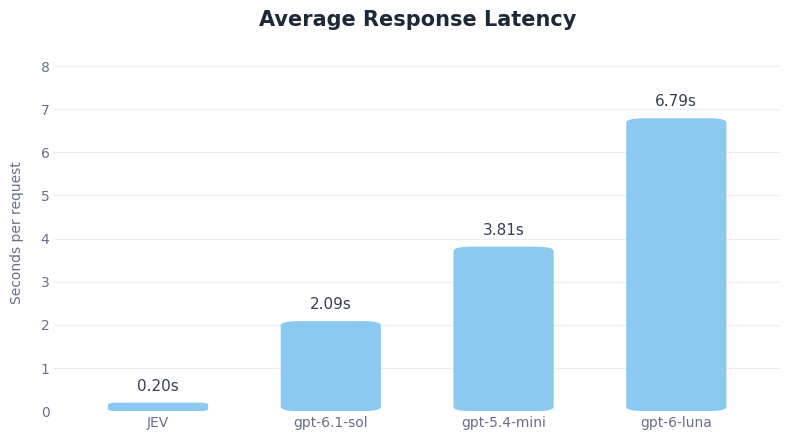

In [4]:
plot_benchmark(
    evaluation_df,
    metric="latency_mean_s",
    title="Average Response Latency",
    ylabel="Seconds per request",
    dataset="Amazon Reviews Multi",
    filename="latency_comparison"
)

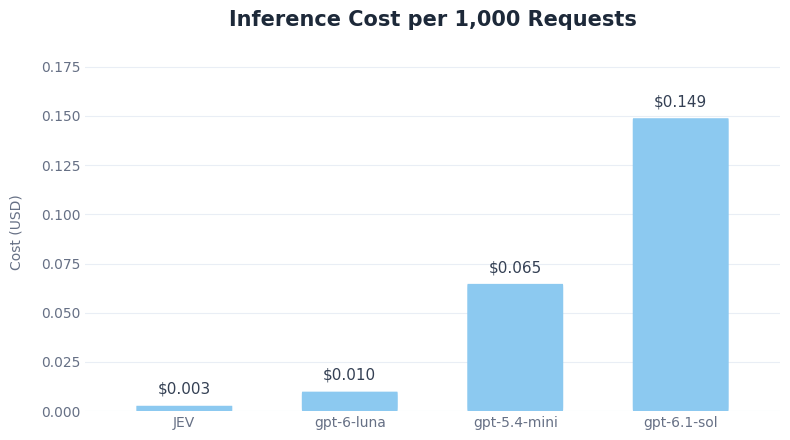

In [5]:
plot_benchmark(
    evaluation_df,
    metric="total_cost_usd",
    title="Inference Cost per 1,000 Requests",
    ylabel="Cost (USD)",
    dataset="Amazon Reviews Multi",
    filename="cost_comparison"
)